In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency
from scipy.stats import chi2
from patsy import dmatrix

import statsmodels.api as sm

# reading datasets from UCI Machine Learning Repository
from ucimlrepo import fetch_ucirepo

## Understand Data


### Data Reading

In [2]:
# # 載在本地端跑比較快

# # fetch dataset 
# cdc_diabetes_health_indicators = fetch_ucirepo(id=891) 
  
# # data (as pandas dataframes) 
# X = cdc_diabetes_health_indicators.data.features 
# y = cdc_diabetes_health_indicators.data.targets 
  
# df = pd.concat([X, y], axis=1)

# # Save dataset
# df.to_csv("cdc_diabetes_health_indicators.csv", index=False)

# print("Dataset saved successfully!")


In [7]:
# Data reading
df = pd.read_csv("cdc_diabetes_health_indicators.csv")

# Data understanding
print(df.shape)
print(df.dtypes)

display(df.head())

(253680, 22)
HighBP                  int64
HighChol                int64
CholCheck               int64
BMI                     int64
Smoker                  int64
Stroke                  int64
HeartDiseaseorAttack    int64
PhysActivity            int64
Fruits                  int64
Veggies                 int64
HvyAlcoholConsump       int64
AnyHealthcare           int64
NoDocbcCost             int64
GenHlth                 int64
MentHlth                int64
PhysHlth                int64
DiffWalk                int64
Sex                     int64
Age                     int64
Education               int64
Income                  int64
Diabetes_binary         int64
dtype: object


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


### Observation of data

In [4]:
#duplicate observations
duplicate_count = df.duplicated().sum()
print("Number of duplicated rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_count / len(df) * 100, 2), "%")

Number of duplicated rows: 24206
Duplicate percentage: 9.54 %


In [5]:
# Missing values
print("\nMissing Values:")
print(df.isna().sum())


Missing Values:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64


In [6]:
# Check variable ranges
print("\nVariable Ranges:")
display(pd.DataFrame({
    "Min": df.min(),
    "Max": df.max(),
    "Unique": df.nunique()
}))


Variable Ranges:


,Min,Max,Unique
HighBP,0,1,2
HighChol,0,1,2
CholCheck,0,1,2
BMI,12,98,84
Smoker,0,1,2
Stroke,0,1,2
HeartDiseaseorAttack,0,1,2
PhysActivity,0,1,2
Fruits,0,1,2
Veggies,0,1,2


##### outlier detection -- BMI

In [7]:
# Outlier detection -- BMI

# BMI Descriptive Statistics
bmi = df["BMI"]

print(bmi.describe())

Q1 = bmi.quantile(0.25)
Q2 = bmi.quantile(0.50)
Q3 = bmi.quantile(0.75)
IQR = Q3 - Q1

mean = bmi.mean()
std = bmi.std()

print("\nMean:", round(mean, 2))
print("Standard Deviation:", round(std, 2))
print("IQR:", IQR)

# BMI Clinical Categories
bins = [0, 18.5, 25, 30, 35, 40, 50, 60, 70, np.inf]

labels = [
    "Underweight (<18.5)",
    "Normal (18.5-24.9)",
    "Overweight (25-29.9)",
    "Obesity I (30-34.9)",
    "Obesity II (35-39.9)",
    "BMI 40-49.9",
    "BMI 50-59.9",
    "BMI 60-69.9",
    "BMI >=70"
]
bmi_groups = pd.cut(
    df["BMI"],
    bins=bins,
    labels=labels,
    right=False
)
bmi_summary = pd.DataFrame({
    "Count": bmi_groups.value_counts(sort=False),
    "Percentage (%)": bmi_groups.value_counts(
        sort=False, normalize=True
    ) * 100
})
display(bmi_summary.round(2))

count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          98.000000
Name: BMI, dtype: float64

Mean: 28.38
Standard Deviation: 6.61
IQR: 7.0


,Count,Percentage (%)
BMI,,
Underweight (<18.5),3127,1.23
Normal (18.5-24.9),68953,27.18
Overweight (25-29.9),93749,36.96
Obesity I (30-34.9),53451,21.07
Obesity II (35-39.9),20663,8.15
BMI 40-49.9,11190,4.41
BMI 50-59.9,1679,0.66
BMI 60-69.9,269,0.11
BMI >=70,599,0.24


In [8]:
# IQR Outlier Detection
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

extreme_lower = Q1 - 3 * IQR
extreme_upper = Q3 + 3 * IQR

outliers = df[(bmi < lower) | (bmi > upper)]

extreme_outliers = df[
    (bmi < extreme_lower) | (bmi > extreme_upper)
]

# Z-score Outlier Detection
z_score = (bmi - mean) / std

z_outliers = df[z_score.abs() > 3]


print("IQR Bounds:", lower, upper)
print("Outliers:", len(outliers))
print("Outlier Rate:", round(len(outliers) / len(df) * 100, 2), "%")

print("\nExtreme IQR Bounds:", extreme_lower, extreme_upper)
print("Extreme Outliers:", len(extreme_outliers))

print("\nNumber of |Z| > 3:", len(z_outliers))
print("Percentage:", round(len(z_outliers) / len(df) * 100, 2), "%")

IQR Bounds: 13.5 41.5
Outliers: 9847
Outlier Rate: 3.88 %

Extreme IQR Bounds: 3.0 52.0
Extreme Outliers: 1707

Number of |Z| > 3: 2963
Percentage: 1.17 %


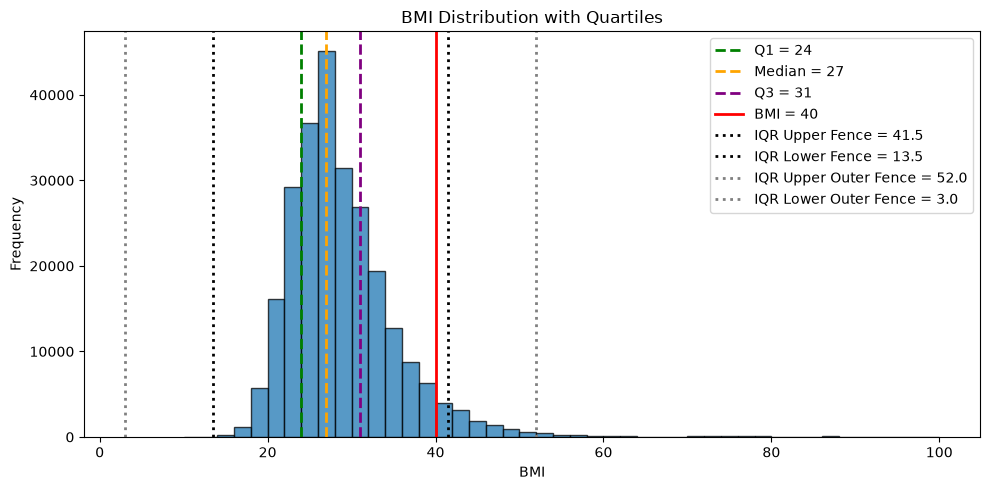

In [9]:
# BMI Distribution

plt.figure(figsize=(10, 5))

# Histogram
plt.hist(bmi, bins=range(10, 101, 2),
         edgecolor="black", alpha=0.75)

# Quartiles
plt.axvline(Q1, color="green", linestyle="--",
            linewidth=2, label=f"Q1 = {Q1:.0f}")

plt.axvline(Q2, color="orange", linestyle="--",
            linewidth=2, label=f"Median = {Q2:.0f}")

plt.axvline(Q3, color="purple", linestyle="--",
            linewidth=2, label=f"Q3 = {Q3:.0f}")

# BMI = 40
plt.axvline(40, color="red", linestyle="-",
            linewidth=2, label="BMI = 40")

# IQR Upper Fence
upper = Q3 + 1.5 * (Q3 - Q1)

plt.axvline(upper, color="black", linestyle=":",
    linewidth=2, label=f"IQR Upper Fence = {upper:.1f}"
)

#IQR Lower Fence
lower = Q1 - 1.5 * (Q3 - Q1)

plt.axvline(lower, color="black", linestyle=":",
    linewidth=2, label=f"IQR Lower Fence = {lower:.1f}"
)

#IQR Upper Outer Fence
outer = Q3 + 3 * (Q3 - Q1)

plt.axvline(outer, color="gray", linestyle=":",
    linewidth=2, label=f"IQR Upper Outer Fence = {outer:.1f}"
)

#IQR Lower Outer Fence
outer_lower = Q1 - 3 * (Q3 - Q1)

plt.axvline(outer_lower, color="gray", linestyle=":",
    linewidth=2, label=f"IQR Lower Outer Fence = {outer_lower:.1f}"
)

plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.title("BMI Distribution with Quartiles")
plt.legend()
plt.tight_layout()
plt.show()

##### Target distribution

In [10]:
# Target distribution
# 了解 Y = 0/1 的比例
print(df["Diabetes_binary"].value_counts())

print("\nTarget percentage:")
print(
    df["Diabetes_binary"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Target percentage:
Diabetes_binary
0    86.07
1    13.93
Name: proportion, dtype: float64


## Descriptive statistics

In [11]:
# 先根據不同data type分類
# Variable Groups
target = "Diabetes_binary"

binary_vars = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

numerical_vars = ["BMI", "MentHlth", "PhysHlth"]

ordinal_vars = ["GenHlth", "Age", "Education", "Income"]

#### numerical


numerical:
MentHlth 的平均數是 3.18 天，但中位數是 0，且 69.25% 的受訪者回報 0 天。
PhysHlth 也有相同現象，63.09% 的受訪者回報 0 天，但平均數達 4.24 天。
這表示兩個變數都存在明顯的零值集中（Zero Concentration）及右偏分布。

,count,mean,std,min,25%,50%,75%,max,IQR
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0,7.0
MentHlth,253680.0,3.18,7.41,0.0,0.0,0.0,2.0,30.0,2.0
PhysHlth,253680.0,4.24,8.72,0.0,0.0,0.0,3.0,30.0,3.0


MentHlth    69.25
PhysHlth    63.09
dtype: float64


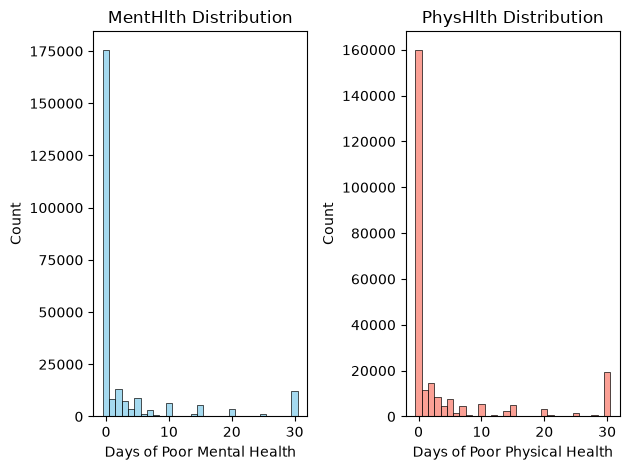

In [12]:
# Numerical Descriptive Statistics
num_summary = df[numerical_vars].describe().T

num_summary["IQR"] = (
    num_summary["75%"] - num_summary["25%"]
)

display(num_summary.round(2))

# 觀察MentHlth, PhysHlth天數是否大量集中於0天
# Percentage of zero values
zero_rate = (
    df[["MentHlth", "PhysHlth"]]
    .eq(0)
    .mean()
    .mul(100)
)

print(zero_rate.round(2))

# MentHlth 長條圖
plt.subplot(1, 2, 1)
sns.histplot(
    data=df,
    x="MentHlth",
    discrete=True,
    color="skyblue",
    edgecolor="black",
)
plt.title(
    f"MentHlth Distribution"
)
plt.xlabel("Days of Poor Mental Health")
plt.ylabel("Count")

# PhysHlth 長條圖
plt.subplot(1, 2, 2)
sns.histplot(
    data=df,
    x="PhysHlth",
    discrete=True,
    color="salmon",
    edgecolor="black",
)
plt.title(
    f"PhysHlth Distribution"
)
plt.xlabel("Days of Poor Physical Health")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

#### Binary

你的 14 個 Binary Predictors 中，我認為最值得注意的是這幾個：
Variable	Percentage (1)	說明
CholCheck	96.27%	幾乎所有人都曾接受膽固醇檢查
AnyHealthcare	95.11%	絕大多數有某種醫療保障
Stroke	4.06%	曾中風者比例較低
HvyAlcoholConsump	5.62%	符合重度飲酒定義的比例較低
NoDocbcCost	8.42%	曾因費用因素而無法就醫的比例較低
PhysActivity	75.65%	多數受訪者回報有身體活動

In [13]:
# Binary Descriptive Statistics
binary_summary = pd.DataFrame({
    "Count (1)": df[binary_vars].sum(),
    "Percentage (1)": df[binary_vars].mean() * 100,
    "Count (0)": (df[binary_vars] == 0).sum()
})

display(binary_summary.round(2))

,Count (1),Percentage (1),Count (0)
HighBP,108829,42.90,144851
HighChol,107591,42.41,146089
CholCheck,244210,96.27,9470
Smoker,112423,44.32,141257
Stroke,10292,4.06,243388
HeartDiseaseorAttack,23893,9.42,229787
PhysActivity,191920,75.65,61760
Fruits,160898,63.43,92782
Veggies,205841,81.14,47839
HvyAlcoholConsump,14256,5.62,239424


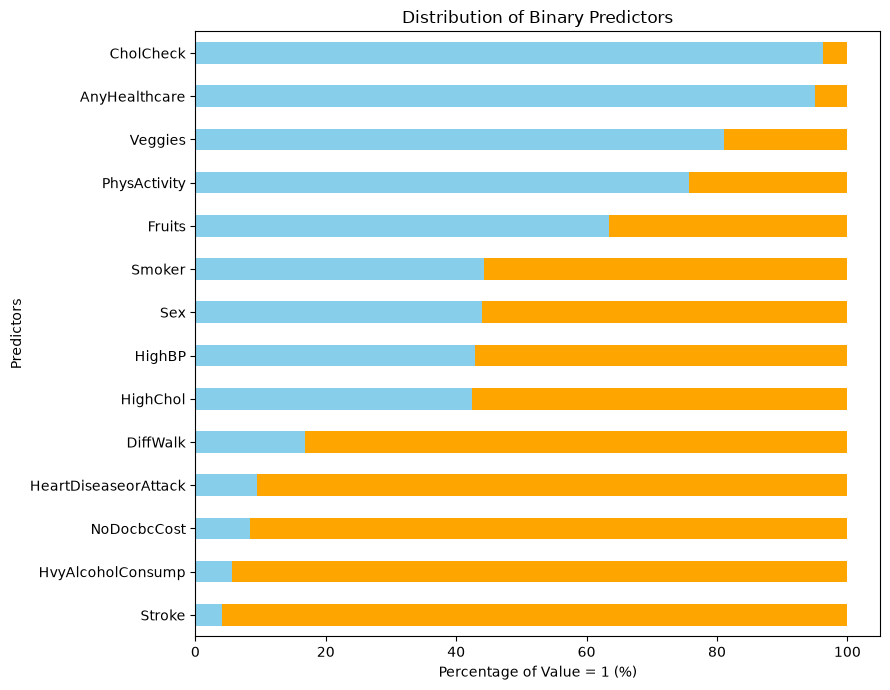

In [14]:
# Binary Variables Distribution
pct_1 = (
    df[binary_vars]
    .mean()
    .mul(100)
    .sort_values()
)
pct_0 = 100 - pct_1

plt.figure(figsize=(9, 7))

pct_1.plot(kind="barh", color="skyblue", label="Value = 1")
pct_0.plot(kind="barh", color="orange", label="Value = 0", left=pct_1)

plt.xlabel("Percentage of Value = 1 (%)")
plt.ylabel("Predictors")
plt.title("Distribution of Binary Predictors")
plt.xlim(0, 105)
plt.tight_layout()
plt.show()

#### Ordinal

Variable	Median	Q1	Q3	值得注意的結果
GenHlth	2	2	3	52.98% 回報 Excellent 或 Very Good
Age	8	6	10	最常見的年齡級距為第 9 組，占 13.10%
Education	5	4	6	第 6 級占 42.31%
Income	7	5	8	最高收入級距占 35.63%

In [15]:
# Ordinal Descriptive Statistics
ordinal_summary = df[ordinal_vars].agg(
    ["min", "median", "max"]
).T

ordinal_summary["Q1"] = df[ordinal_vars].quantile(0.25)
ordinal_summary["Q3"] = df[ordinal_vars].quantile(0.75)

display(ordinal_summary)

# Ordinal Category Frequencies
for col in ordinal_vars:
    display(
        df[col].value_counts(
            normalize=True
        ).sort_index().mul(100).round(2)
    )

,min,median,max,Q1,Q3
GenHlth,1.0,2.0,5.0,2.0,3.0
Age,1.0,8.0,13.0,6.0,10.0
Education,1.0,5.0,6.0,4.0,6.0
Income,1.0,7.0,8.0,5.0,8.0


GenHlth
1    17.86
2    35.12
3    29.82
4    12.44
5     4.76
Name: proportion, dtype: float64

Age
1      2.25
2      3.00
3      4.38
4      5.45
5      6.37
6      7.81
7     10.37
8     12.15
9     13.10
10    12.69
11     9.28
12     6.30
13     6.84
Name: proportion, dtype: float64

Education
1     0.07
2     1.59
3     3.74
4    24.74
5    27.56
6    42.31
Name: proportion, dtype: float64

Income
1     3.87
2     4.64
3     6.30
4     7.94
5    10.20
6    14.38
7    17.04
8    35.63
Name: proportion, dtype: float64

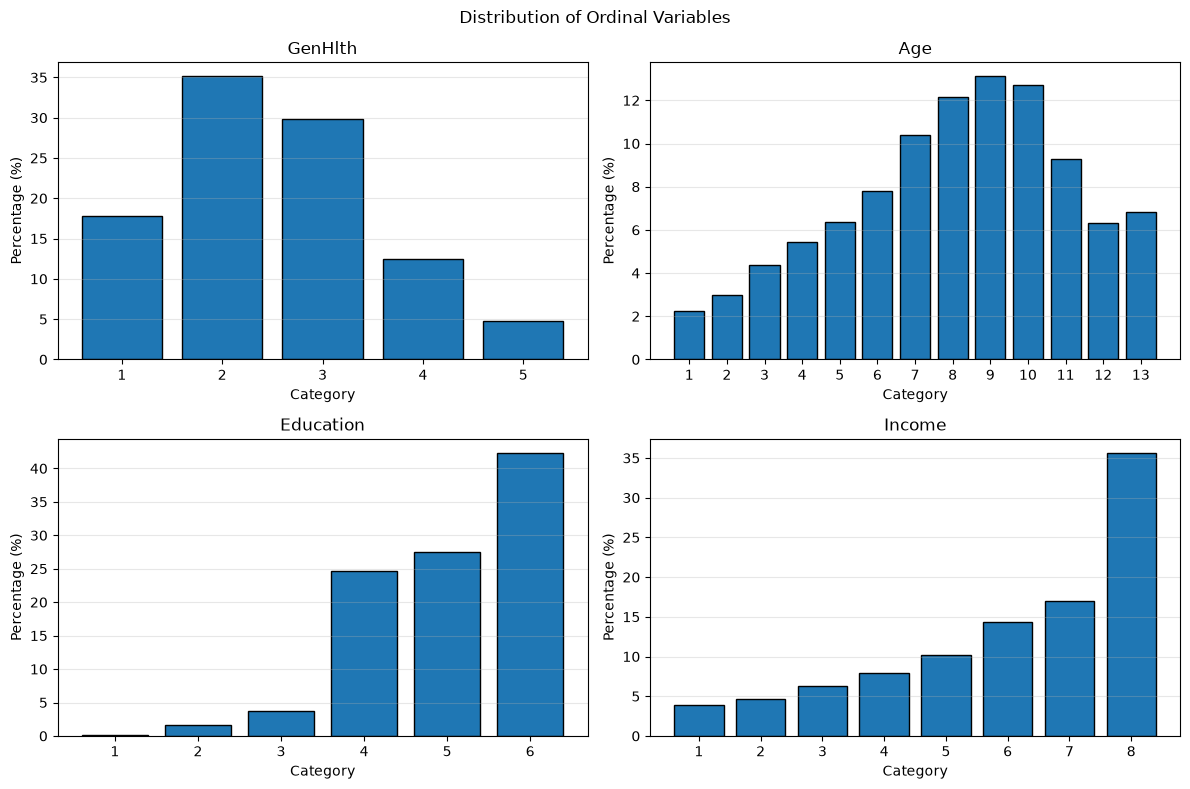

In [16]:
ordinal_vars = ["GenHlth", "Age", "Education", "Income"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, ordinal_vars):

    pct = (
        df[col]
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    ax.bar(pct.index, pct.values, edgecolor="black")

    ax.set_title(col)
    ax.set_xlabel("Category")
    ax.set_ylabel("Percentage (%)")
    ax.set_xticks(pct.index)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Distribution of Ordinal Variables")
plt.tight_layout()
plt.show()

## EDA

### Correlation Anlysis

1. Predictor vs. Predictor：了解 predictors 之間的相關程度，找出潛在的 Multicollinearity。
2. Predictor vs. Target：了解哪些 predictors 與 Diabetes_binary 存在較強的單變數關聯。
3. Statistical Tests：根據變數類型進行適當的統計檢定，例如 Welch's t-test、Chi-square Test。
需要特別強調：這些都是初步關聯分析，不會在此階段根據相關係數或 p-value 刪除 predictors。

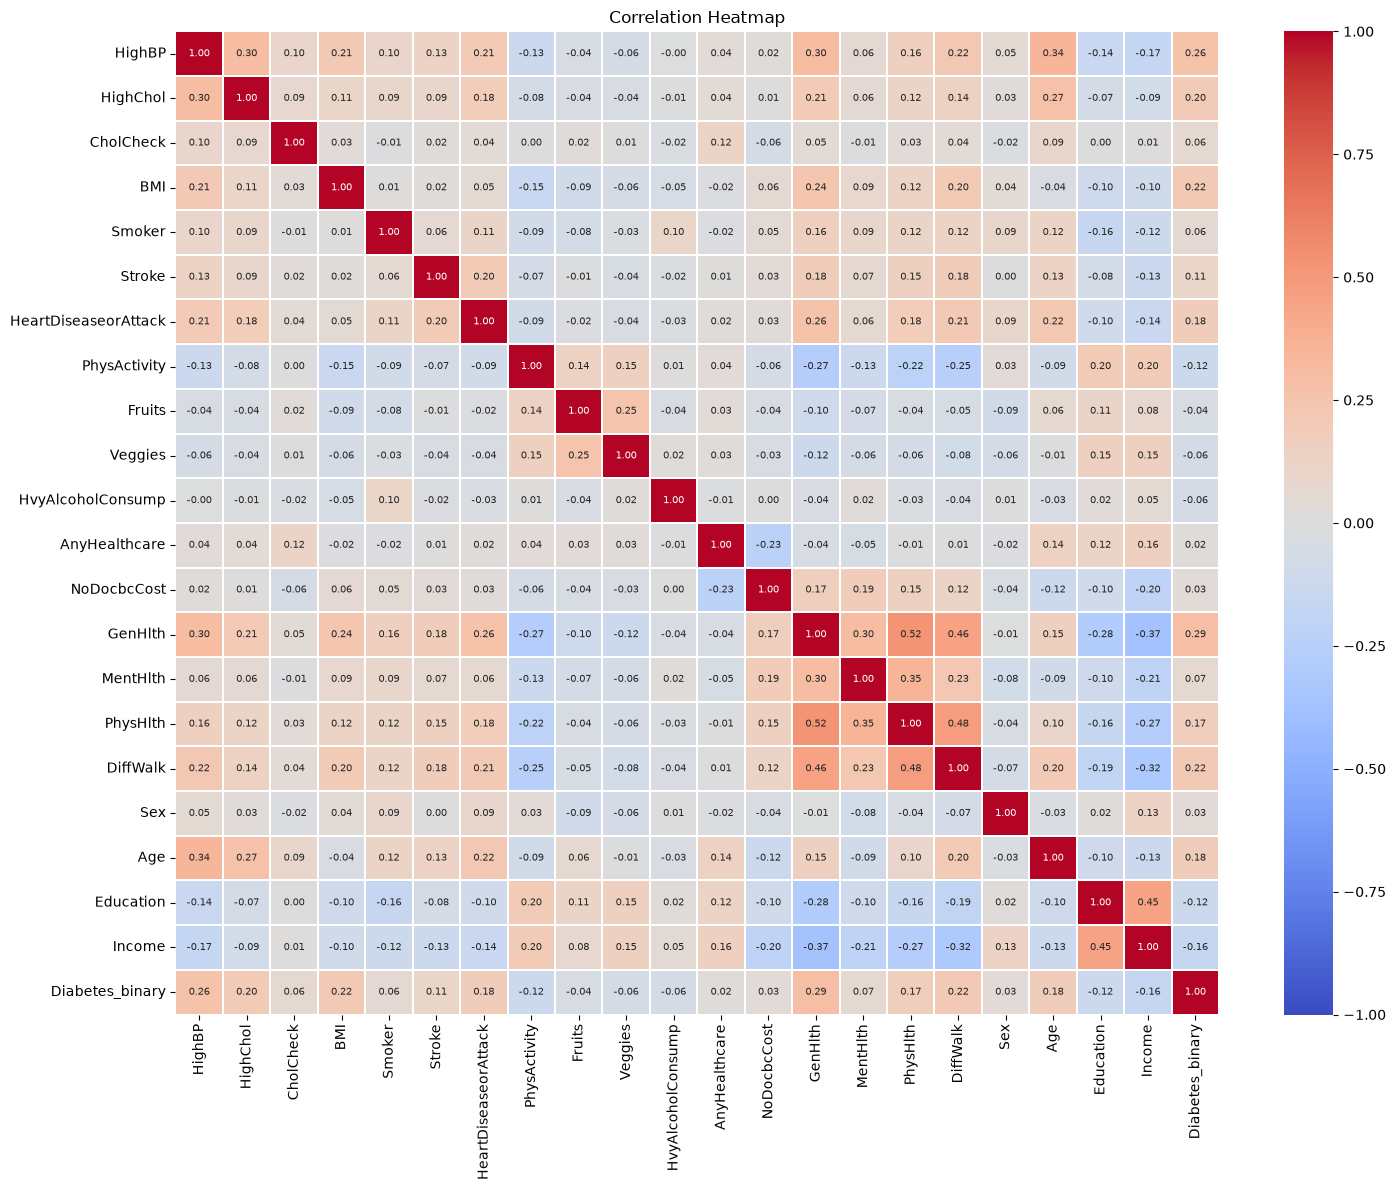

In [17]:
# Correlation matrix
corr = df.corr(method="pearson")

# Correlation Heatmap
plt.figure(figsize=(15, 12))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot_kws={"size": 7}
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

##### Predictor-to-Predictor Correlation


In [18]:
# Predictor-to-Predictor Correlation
X_corr = df.drop(columns="Diabetes_binary").corr()

# Keep upper triangle only
upper = X_corr.where(
    np.triu(np.ones(X_corr.shape), k=1).astype(bool)
)

# Extract and rank correlations
corr_pairs = (
    upper.stack()
    .rename("Correlation")
    .reset_index()
)

corr_pairs.columns = [
    "Predictor 1", "Predictor 2", "Correlation"
]

corr_pairs["Absolute Correlation"] = (
    corr_pairs["Correlation"].abs()
)

corr_pairs = corr_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
)

display(corr_pairs.head(15).round(3))

,Predictor 1,Predictor 2,Correlation,Absolute Correlation
288,GenHlth,PhysHlth,0.524,0.524
331,PhysHlth,DiffWalk,0.478,0.478
289,GenHlth,DiffWalk,0.457,0.457
419,Education,Income,0.449,0.449
293,GenHlth,Income,-0.370,0.370
309,MentHlth,PhysHlth,0.354,0.354
18,HighBP,Age,0.344,0.344
356,DiffWalk,Income,-0.320,0.320
287,GenHlth,MentHlth,0.302,0.302
13,HighBP,GenHlth,0.301,0.301


##### Correlation with Target

,Correlation
Income,-0.1639
Education,-0.1245
PhysActivity,-0.1181
HvyAlcoholConsump,-0.0571
Veggies,-0.0566
Fruits,-0.0408
AnyHealthcare,0.0163
Sex,0.0314
NoDocbcCost,0.0314
Smoker,0.0608


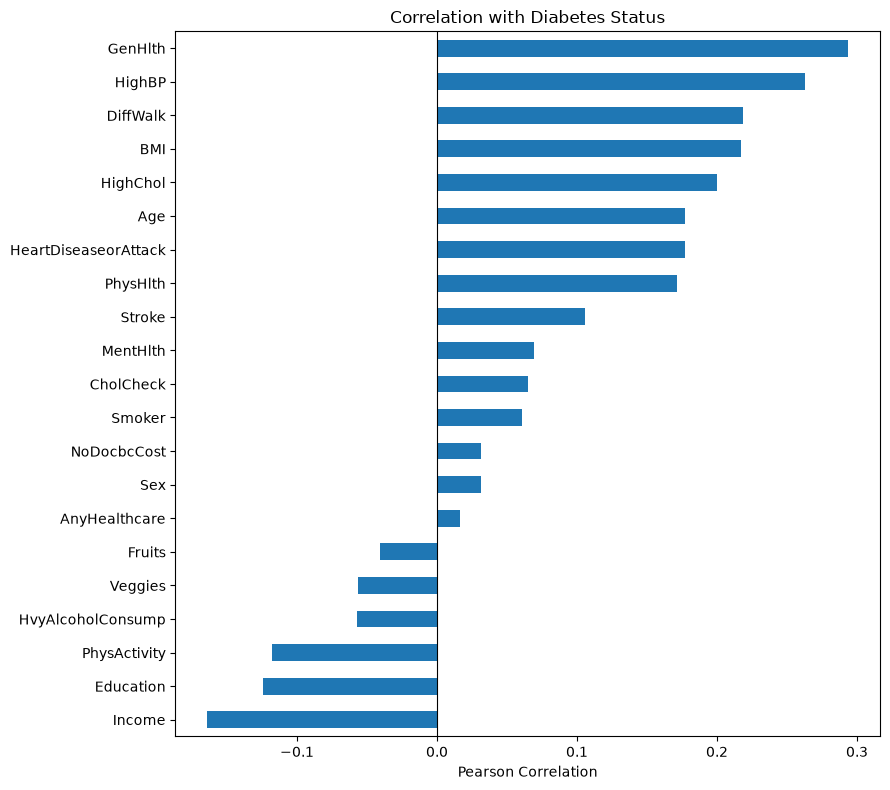

In [19]:
# Correlation with Target
target_corr = (
    corr["Diabetes_binary"]
    .drop("Diabetes_binary")
    .sort_values()
)

display(target_corr.to_frame("Correlation").round(4))

# Horizontal bar chart
plt.figure(figsize=(9, 8))

target_corr.plot(kind="barh")

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson Correlation")
plt.title("Correlation with Diabetes Status")
plt.tight_layout()
plt.show()

In [20]:
# Pearson vs. Spearman Correlation

ordinal_vars = ["GenHlth", "Age", "Education", "Income"]

for col in ordinal_vars:
    pearson = df[col].corr(
        df["Diabetes_binary"], method="pearson"
    )

    spearman = df[col].corr(
        df["Diabetes_binary"], method="spearman"
    )

    print(
        f"{col}: Pearson = {pearson:.4f}, "
        f"Spearman = {spearman:.4f}"
    )

GenHlth: Pearson = 0.2936, Spearman = 0.2877
Age: Pearson = 0.1774, Spearman = 0.1777
Education: Pearson = -0.1245, Spearman = -0.1200
Income: Pearson = -0.1639, Spearman = -0.1633


##### test

In [21]:
# 針對不同變數類型進行統計檢定
# Numerical vs. Binary Target：Welch's t-test
numerical_vars = ["BMI", "MentHlth", "PhysHlth"]

t_results = []

for col in numerical_vars:
    group0 = df.loc[df["Diabetes_binary"] == 0, col]
    group1 = df.loc[df["Diabetes_binary"] == 1, col]

    t_stat, p_value = ttest_ind(
        group1, group0, equal_var=False
    )

    t_results.append({
        "Variable": col,
        "Mean (Y=0)": group0.mean(),
        "Mean (Y=1)": group1.mean(),
        "Mean Difference": group1.mean() - group0.mean(),
        "t-statistic": t_stat,
        "p-value": p_value
    })

t_results = pd.DataFrame(t_results)


for col in ["BMI", "MentHlth", "PhysHlth"]:
    group0 = df.loc[df["Diabetes_binary"] == 0, col]
    group1 = df.loc[df["Diabetes_binary"] == 1, col]

    result = ttest_ind(group1, group0, equal_var=False)
    ci = result.confidence_interval(confidence_level=0.95)

    print(
        f"{col}: "
        f"Difference = {group1.mean()-group0.mean():.4f}, "
        f"95% CI = [{ci.low:.4f}, {ci.high:.4f}], "
        f"t = {result.statistic:.4f}, "
        f"p = {result.pvalue:.3g}"
    )

display(t_results.round(4))

BMI: Difference = 4.1382, 95% CI = [4.0571, 4.2194], t = 99.9196, p = 0
MentHlth: Difference = 1.4838, 95% CI = [1.3858, 1.5817], t = 29.6948, p = 7.93e-192
PhysHlth: Difference = 4.3134, 95% CI = [4.1908, 4.4360], t = 68.9688, p = 0


,Variable,Mean (Y=0),Mean (Y=1),Mean Difference,t-statistic,p-value
0,BMI,27.8058,31.9440,4.1382,99.9196,0.0
1,MentHlth,2.9780,4.4618,1.4838,29.6948,0.0
2,PhysHlth,3.6411,7.9545,4.3134,68.9688,0.0


In [22]:
#Categorical vs. Binary Target：Chi-square Test
categorical_vars = binary_vars + ordinal_vars

chi_results = []

for col in categorical_vars:
    table = pd.crosstab(
        df[col],
        df["Diabetes_binary"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        table, correction=False
    )

    chi_results.append({
        "Variable": col,
        "Chi-square": chi2,
        "df": dof,
        "p-value": p_value
    })

chi_results = pd.DataFrame(chi_results)

display(
    chi_results.sort_values("p-value").round(4)
)

,Variable,Chi-square,df,p-value
0,HighBP,17563.9813,1,0.0
1,HighChol,10175.2451,1,0.0
5,HeartDiseaseorAttack,7972.9084,1,0.0
4,Stroke,2840.4651,1,0.0
6,PhysActivity,3540.2142,1,0.0
12,DiffWalk,12094.0053,1,0.0
15,Age,8795.0506,12,0.0
14,GenHlth,22728.0691,4,0.0
17,Income,7003.7151,7,0.0
16,Education,4027.1123,5,0.0


,Variable,Chi-square,df,p-value,Cramer's V
14,GenHlth,22728.0691,4,0.0,0.2993
0,HighBP,17563.9813,1,0.0,0.2631
12,DiffWalk,12094.0053,1,0.0,0.2183
1,HighChol,10175.2451,1,0.0,0.2003
15,Age,8795.0506,12,0.0,0.1862
5,HeartDiseaseorAttack,7972.9084,1,0.0,0.1773
17,Income,7003.7151,7,0.0,0.1662
16,Education,4027.1123,5,0.0,0.1260
6,PhysActivity,3540.2142,1,0.0,0.1181
4,Stroke,2840.4651,1,0.0,0.1058


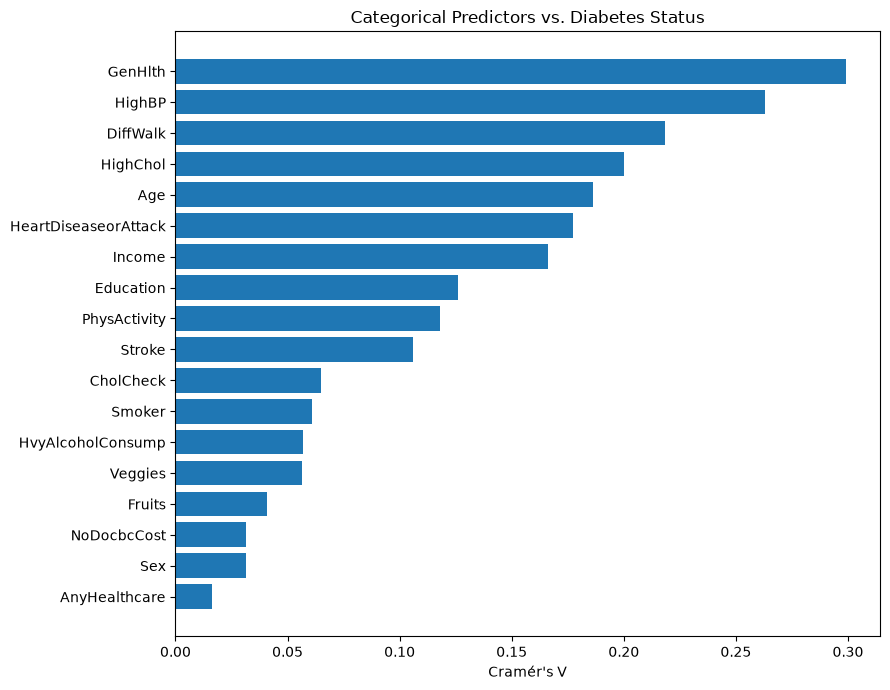

In [23]:
# 進一步檢測關聯強度 -- Cramer's V

categorical_vars = binary_vars + ordinal_vars

results = []

for col in categorical_vars:
    table = pd.crosstab(df[col], df["Diabetes_binary"])

    chi2, p_value, dof, expected = chi2_contingency(
        table, correction=False
    )

    n = table.to_numpy().sum()

    cramers_v = np.sqrt(
        chi2 / (n * (min(table.shape) - 1))
    )

    results.append({
        "Variable": col,
        "Chi-square": chi2,
        "df": dof,
        "p-value": p_value,
        "Cramer's V": cramers_v
    })

cramers_results = pd.DataFrame(results)

cramers_results = cramers_results.sort_values(
    "Cramer's V", ascending=False
)

display(cramers_results.round(4))

# Cramer's V Bar Chart
plt.figure(figsize=(9, 7))

plt.barh(
    cramers_results["Variable"],
    cramers_results["Cramer's V"]
)

plt.gca().invert_yaxis()
plt.xlabel("Cramér's V")
plt.title("Categorical Predictors vs. Diabetes Status")
plt.tight_layout()
plt.show()

## Full Model 

In [32]:
# Define predictors and target
X = df.drop(columns="Diabetes_binary")
y = df["Diabetes_binary"]

# Add intercept
X = sm.add_constant(X)

# Fit Full Logistic Regression
full_model = sm.Logit(y, X).fit(maxiter=200)

# Model summary
print(full_model.summary())

print("AIC:", full_model.aic)
print("BIC:", full_model.bic)
print("Log-Likelihood:", full_model.llf)

Optimization terminated successfully.
         Current function value: 0.319662
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:        Diabetes_binary   No. Observations:               253680
Model:                          Logit   Df Residuals:                   253658
Method:                           MLE   Df Model:                           21
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.2083
Time:                        11:41:09   Log-Likelihood:                -81092.
converged:                       True   LL-Null:                   -1.0242e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -7.8362      0.094    -83.760      0.000      -8.020      -7.653

### VIF

In [25]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_results = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

vif_results = (
    vif_results[vif_results["Variable"] != "const"]
    .sort_values("VIF", ascending=False)
)

display(vif_results.round(3))

,Variable,VIF
14,GenHlth,1.796
16,PhysHlth,1.623
17,DiffWalk,1.534
21,Income,1.504
19,Age,1.350
1,HighBP,1.331
20,Education,1.326
15,MentHlth,1.239
2,HighChol,1.173
7,HeartDiseaseorAttack,1.172


### Ordinal Encoding Comparison
比較四個 Ordinal Variables 是否應該使用 Dummy Encoding
使用 LRT 評估 Dummy Encoding 是否能顯著改善擬合

這個 LRT 檢定的假設是：

H_0:{Ordinal Variables 的 logit 效果可以由線性級距編碼描述}


H_1:{至少一個 Ordinal Variable 需要更彈性的類別效果}


In [35]:
ordinal_vars = ["GenHlth", "Age", "Education", "Income"]

# Dummy Encoding
X_dummy = pd.get_dummies(
    df.drop(columns="Diabetes_binary"),
    columns=ordinal_vars,
    drop_first=True,
    dtype=float
)

X_dummy = sm.add_constant(X_dummy)

# Fit Dummy-Encoded Full Model
dummy_model = sm.Logit(
    df["Diabetes_binary"], X_dummy
).fit(maxiter=200)

# Likelihood Ratio Test
LR = 2 * (dummy_model.llf - full_model.llf)

df_diff = int(
    dummy_model.df_model - full_model.df_model
)

p_value = chi2.sf(LR, df_diff)

print(f"Original Model LL: {full_model.llf:.2f}")
print(f"Dummy Model LL: {dummy_model.llf:.2f}")
print(f"LR Statistic: {LR:.2f}")
print(f"df Difference: {df_diff}")
print(f"p-value: {p_value:.4g}")

print(f"\nOriginal AIC: {full_model.aic:.2f}")
print(f"Dummy AIC: {dummy_model.aic:.2f}")
print(f"Original BIC: {full_model.bic:.2f}")
print(f"Dummy BIC: {dummy_model.bic:.2f}")

Optimization terminated successfully.
         Current function value: 0.316944
         Iterations 8
Original Model LL: -81091.82
Dummy Model LL: -80402.31
LR Statistic: 1379.00
df Difference: 24
p-value: 1.523e-276

Original AIC: 162227.63
Dummy AIC: 160896.63
Original BIC: 162457.40
Dummy BIC: 161377.04


#### Individual Ordinal Encoding LRT

In [36]:
ordinal_vars = ["GenHlth", "Age", "Education", "Income"]

results = []

for col in ordinal_vars:

    # Only dummy-encode one ordinal variable
    X_test = pd.get_dummies(
        df.drop(columns="Diabetes_binary"),
        columns=[col],
        drop_first=True,
        dtype=float
    )

    X_test = sm.add_constant(X_test)

    model_test = sm.Logit(
        df["Diabetes_binary"], X_test
    ).fit(maxiter=200, disp=False)

    # Compare with original full model
    LR = 2 * (model_test.llf - full_model.llf)
    df_diff = int(model_test.df_model - full_model.df_model)
    p_value = chi2.sf(LR, df_diff)

    results.append({
        "Variable": col,
        "LR Statistic": LR,
        "df Difference": df_diff,
        "p-value": p_value,
        "AIC": model_test.aic,
        "BIC": model_test.bic,
        "Delta AIC": model_test.aic - full_model.aic,
        "Delta BIC": model_test.bic - full_model.bic
    })

encoding_results = pd.DataFrame(results)

display(
    encoding_results.round(4)
)

,Variable,LR Statistic,df Difference,p-value,AIC,BIC,Delta AIC,Delta BIC
0,GenHlth,410.8712,3,0.0,161822.7618,162083.8575,-404.8712,-373.5397
1,Age,892.6226,11,0.0,161357.0104,161701.6567,-870.6226,-755.7405
2,Education,32.9158,4,0.0,162202.7171,162474.2567,-24.9158,16.8595
3,Income,30.3598,6,0.0,162209.2732,162501.7004,-18.3598,44.3032


#### Mixed Encoding Model

In [39]:
# GenHlth and Age: Dummy Encoding
X_mixed = pd.get_dummies(
    df.drop(columns="Diabetes_binary"),
    columns=["GenHlth", "Age"],
    drop_first=True,
    dtype=float
)

X_mixed = sm.add_constant(X_mixed)

# Fit Mixed Encoding Full Model
mixed_model = sm.Logit(
    df["Diabetes_binary"], X_mixed
).fit(maxiter=200)

print(mixed_model.summary())

print("Converged:", mixed_model.mle_retvals["converged"])

Optimization terminated successfully.
         Current function value: 0.317056
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:        Diabetes_binary   No. Observations:               253680
Model:                          Logit   Df Residuals:                   253644
Method:                           MLE   Df Model:                           35
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.2147
Time:                        00:47:00   Log-Likelihood:                -80431.
converged:                       True   LL-Null:                   -1.0242e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -7.9261      0.147    -53.995      0.000      -8.214      -7.638

In [40]:
# compare all three models
comparison = pd.DataFrame({
    "Model": [
        "Original Full",
        "Mixed Full",
        "Dummy Full"
    ],
    "Log-Likelihood": [
        full_model.llf,
        mixed_model.llf,
        dummy_model.llf
    ],
    "df_model": [
        full_model.df_model,
        mixed_model.df_model,
        dummy_model.df_model
    ],
    "AIC": [
        full_model.aic,
        mixed_model.aic,
        dummy_model.aic
    ],
    "BIC": [
        full_model.bic,
        mixed_model.bic,
        dummy_model.bic
    ]
})

display(comparison.round(2))

,Model,Log-Likelihood,df_model,AIC,BIC
0,Original Full,-81091.82,21.0,162227.63,162457.40
1,Mixed Full,-80430.71,35.0,160933.43,161309.40
2,Dummy Full,-80402.31,45.0,160896.63,161377.04


## Variable Selection

In [8]:
# Define Predictor Groups
ordinal_dummy = ["GenHlth", "Age"]

groups = {}

for col in df.drop(columns="Diabetes_binary").columns:
    if col in ordinal_dummy:
        groups[col] = [
            c for c in X_mixed.columns
            if c.startswith(col + "_")
        ]
    else:
        groups[col] = [col]

print(f"Number of Predictor Groups: {len(groups)}")

for name, cols in groups.items():
    print(f"{name}: {len(cols)} coefficient(s)")

NameError: name 'X_mixed' is not defined

In [36]:
# 建立共同的LRT函式
# Cache fitted models
model_cache = {}

all_groups = list(groups.keys())

# Save existing Mixed Full Model
model_cache[tuple(sorted(all_groups))] = mixed_model


# 根據目前保留的 Predictor Groups 自動建立模型
def fit_model(selected):
    key = tuple(sorted(selected))

    if key not in model_cache:
        cols = ["const"]

        for name in all_groups:
            if name in selected:
                cols.extend(groups[name])

        model = sm.Logit(y, X_mixed[cols]).fit(
            maxiter=200, disp=False
        )

        if not model.mle_retvals["converged"]:
            raise RuntimeError(
                f"Model did not converge: {key}"
            )

        model_cache[key] = model

    return model_cache[key]


def lrt(smaller, larger):
    model_small = fit_model(smaller)
    model_large = fit_model(larger)

    LR = max(
        0, 2 * (model_large.llf - model_small.llf)
    )

    df_diff = int(
        model_large.df_model - model_small.df_model
    )

    p_value = chi2.sf(LR, df_diff)

    return LR, df_diff, p_value

NameError: name 'mixed_model' is not defined

In [49]:
def forward_selection(alpha=0.05):
    selected = []
    history = []

    while True:
        candidates = []

        for var in all_groups:
            if var not in selected:
                LR, df_diff, p = lrt(
                    selected, selected + [var]
                )
                candidates.append((var, LR, df_diff, p))

        if not candidates:
            break

        var, LR, df_diff, p = min(
            candidates, key=lambda x: x[3]
        )

        if p >= alpha:
            break

        selected.append(var)

        history.append({
            "Step": len(history) + 1,
            "Action": "Add",
            "Variable": var,
            "LR": LR,
            "df": df_diff,
            "p-value": p,
            "Groups": len(selected)
        })

    return selected, fit_model(selected), pd.DataFrame(history)


def backward_selection(alpha=0.05):
    selected = all_groups.copy()
    history = []

    while selected:
        candidates = []

        for var in selected:
            reduced = [
                x for x in selected if x != var
            ]

            LR, df_diff, p = lrt(
                reduced, selected
            )

            candidates.append((var, LR, df_diff, p))

        var, LR, df_diff, p = max(
            candidates, key=lambda x: x[3]
        )

        if p <= alpha:
            break

        selected.remove(var)

        history.append({
            "Step": len(history) + 1,
            "Action": "Remove",
            "Variable": var,
            "LR": LR,
            "df": df_diff,
            "p-value": p,
            "Groups": len(selected)
        })

    return selected, fit_model(selected), pd.DataFrame(history)


def stepwise_selection(alpha_enter=0.05,
                       alpha_remove=0.05):

    selected = []
    history = []
    visited = {tuple(sorted(selected))}

    for _ in range(100):

        # Forward step
        candidates = []

        for var in all_groups:
            if var not in selected:
                LR, df_diff, p = lrt(
                    selected, selected + [var]
                )
                candidates.append((var, LR, df_diff, p))

        if not candidates:
            break

        var, LR, df_diff, p = min(
            candidates, key=lambda x: x[3]
        )

        if p >= alpha_enter:
            break

        next_selected = selected + [var]
        key = tuple(sorted(next_selected))

        if key in visited:
            print("Cycle detected; stopping Stepwise.")
            break

        selected = next_selected
        visited.add(key)

        history.append({
            "Step": len(history) + 1,
            "Action": "Add",
            "Variable": var,
            "LR": LR,
            "df": df_diff,
            "p-value": p,
            "Groups": len(selected)
        })

        # Backward checks
        while selected:
            remove_candidates = []

            for name in selected:
                reduced = [
                    x for x in selected if x != name
                ]

                LR_r, df_r, p_r = lrt(
                    reduced, selected
                )

                remove_candidates.append(
                    (name, LR_r, df_r, p_r)
                )

            name, LR_r, df_r, p_r = max(
                remove_candidates, key=lambda x: x[3]
            )

            if p_r <= alpha_remove:
                break

            next_selected = [
                x for x in selected if x != name
            ]
            key = tuple(sorted(next_selected))

            if key in visited:
                print("Cycle detected; stopping Stepwise.")
                return (
                    selected,
                    fit_model(selected),
                    pd.DataFrame(history)
                )

            selected = next_selected
            visited.add(key)

            history.append({
                "Step": len(history) + 1,
                "Action": "Remove",
                "Variable": name,
                "LR": LR_r,
                "df": df_r,
                "p-value": p_r,
                "Groups": len(selected)
            })

    return selected, fit_model(selected), pd.DataFrame(history)

In [ ]:
# # Run three selection methods
# forward_vars, forward_model, forward_history = (
#     forward_selection(alpha=0.05)
# )

# backward_vars, backward_model, backward_history = (
#     backward_selection(alpha=0.05)
# )

# stepwise_vars, stepwise_model, stepwise_history = (
#     stepwise_selection(
#         alpha_enter=0.05,
#         alpha_remove=0.05
#     )
# )

# # Selection histories
# print("=== Forward Selection ===")
# display(forward_history)

# print("=== Backward Elimination ===")
# display(backward_history)

# print("=== Bidirectional Stepwise ===")
# display(stepwise_history)

=== Forward Selection ===


,Step,Action,Variable,LR,df,p-value,Groups
0,1,Add,HighBP,17760.742355,1,0.000000e+00,1
1,2,Add,HighChol,4292.893538,1,0.000000e+00,2
2,3,Add,BMI,5939.357839,1,0.000000e+00,3
3,4,Add,HeartDiseaseorAttack,2106.059904,1,0.000000e+00,4
4,5,Add,GenHlth,8456.996484,4,0.000000e+00,5
5,6,Add,Age,3538.978058,12,0.000000e+00,6
6,7,Add,HvyAlcoholConsump,530.563344,1,2.130053e-117,7
7,8,Add,CholCheck,416.518140,1,1.397403e-92,8
8,9,Add,Income,351.068577,1,2.479949e-78,9
9,10,Add,Sex,376.073209,1,8.910393e-84,10


=== Backward Elimination ===


,Step,Action,Variable,LR,df,p-value,Groups
0,1,Remove,NoDocbcCost,0.336423,1,0.561901,20
1,2,Remove,Fruits,2.734260,1,0.098217,19


=== Bidirectional Stepwise ===


,Step,Action,Variable,LR,df,p-value,Groups
0,1,Add,HighBP,17760.742355,1,0.000000e+00,1
1,2,Add,HighChol,4292.893538,1,0.000000e+00,2
2,3,Add,BMI,5939.357839,1,0.000000e+00,3
3,4,Add,HeartDiseaseorAttack,2106.059904,1,0.000000e+00,4
4,5,Add,GenHlth,8456.996484,4,0.000000e+00,5
5,6,Add,Age,3538.978058,12,0.000000e+00,6
6,7,Add,HvyAlcoholConsump,530.563344,1,2.130053e-117,7
7,8,Add,CholCheck,416.518140,1,1.397403e-92,8
8,9,Add,Income,351.068577,1,2.479949e-78,9
9,10,Add,Sex,376.073209,1,8.910393e-84,10


In [ ]:
# models = {
#     "Mixed Full": (all_groups, mixed_model),
#     "Forward": (forward_vars, forward_model),
#     "Backward": (backward_vars, backward_model),
#     "Stepwise": (stepwise_vars, stepwise_model)
# }

# comparison = []

# for name, (variables, model) in models.items():
#     comparison.append({
#         "Model": name,
#         "Groups": len(variables),
#         "Coefficients": int(model.df_model),
#         "Log-Likelihood": model.llf,
#         "AIC": model.aic,
#         "BIC": model.bic
#     })

# comparison_df = pd.DataFrame(comparison)

# display(comparison_df.round(2))

NameError: name 'forward_vars' is not defined

In [ ]:
# # 比較最終模型
# for name, (variables, model) in models.items():
#     print(f"\n{name} ({len(variables)} groups)")
#     print(", ".join(variables))


Mixed Full (21 groups)
HighBP, HighChol, CholCheck, BMI, Smoker, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, AnyHealthcare, NoDocbcCost, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income

Forward (19 groups)
HighBP, HighChol, BMI, HeartDiseaseorAttack, GenHlth, Age, HvyAlcoholConsump, CholCheck, Income, Sex, DiffWalk, Stroke, Education, PhysHlth, PhysActivity, MentHlth, Smoker, Veggies, AnyHealthcare

Backward (19 groups)
HighBP, HighChol, CholCheck, BMI, Smoker, Stroke, HeartDiseaseorAttack, PhysActivity, Veggies, HvyAlcoholConsump, AnyHealthcare, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income

Stepwise (19 groups)
HighBP, HighChol, BMI, HeartDiseaseorAttack, GenHlth, Age, HvyAlcoholConsump, CholCheck, Income, Sex, DiffWalk, Stroke, Education, PhysHlth, PhysActivity, MentHlth, Smoker, Veggies, AnyHealthcare


#### save model
不要再叫我開機重跑了

In [11]:
# 紀錄 selected model，避免開機重跑
# Selected Predictor Groups
backward_vars = [
    "HighBP", "HighChol", "CholCheck", "BMI",
    "Smoker", "Stroke", "HeartDiseaseorAttack",
    "PhysActivity", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "GenHlth", "MentHlth",
    "PhysHlth", "DiffWalk", "Sex", "Age",
    "Education", "Income"
]

y = df["Diabetes_binary"]

X_mixed = pd.get_dummies(
    df.drop(columns="Diabetes_binary"),
    columns=["GenHlth", "Age"],
    drop_first=True,
    dtype=float
)

X_mixed = sm.add_constant(X_mixed)


# 重建 Selected Model 給後面分析用
selected_cols = [
    "const", "HighBP", "HighChol", "CholCheck",
    "BMI", "Smoker", "Stroke", "HeartDiseaseorAttack",
    "PhysActivity", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "MentHlth", "PhysHlth",
    "DiffWalk", "Sex", "Education", "Income"
]

selected_cols += [
    col for col in X_mixed.columns
    if col.startswith(("GenHlth_", "Age_"))
]

X_selected = X_mixed[selected_cols]

backward_model = sm.Logit(
    y, X_selected
).fit(maxiter=200)

print("AIC:", backward_model.aic)
print("BIC:", backward_model.bic)

Optimization terminated successfully.
         Current function value: 0.317062
         Iterations 8
AIC: 160932.49642885767
BIC: 161287.58661177088


In [34]:
# Save selected model
backward_model.save("selected_logit_model.pickle")

backward_model = sm.load("selected_logit_model.pickle")

backward_model.params
backward_model.predict()
backward_model.aic
backward_model.bic

np.float64(161287.58661177088)

#### Linearity in the Logit

（對數勝算比的線性假定） 是邏輯式迴歸（Logistic Regression）中最核心、但也最常被忽略的基本假設（Assumption）之一。簡單來說，它的意思指的是：「模型中的連續型自變數（Continuous Independent Variable, $X$），與邏輯式迴歸的對數勝算比（Log-Odds, 即 Logit）之間，必須呈現『直線的線性關係』。」

先前資料分析時發現BMI、MentHlth、PhysHlth三個變數的資料有右偏、某些值較多的現象，因此使用Linearity in the Logit分析。

小結論：
BMI： 呈現明顯非線性效果（LR = 1400.86，p < 0.001），且 AIC、BIC 均大幅改善，建議改用 Cubic Spline。

MentHlth： LRT 顯著，但 AIC 與 BIC 判斷不同；考量模型簡潔性，暫時保留線性項。

PhysHlth： LRT 不顯著（p = 0.4769），AIC、BIC 亦未改善，因此保留線性項。


In [38]:
# Debug

# Rebuild predictor groups
ordinal_dummy = ["GenHlth", "Age"]

groups = {}

for col in df.drop(columns="Diabetes_binary").columns:
    if col in ordinal_dummy:
        groups[col] = [
            c for c in X_mixed.columns
            if c.startswith(col + "_")
        ]
    else:
        groups[col] = [col]

# Verify
print("GenHlth:", groups["GenHlth"])
print("Age:", groups["Age"])
print("Number of groups:", len(groups))

GenHlth: ['GenHlth_2', 'GenHlth_3', 'GenHlth_4', 'GenHlth_5']
Age: ['Age_2', 'Age_3', 'Age_4', 'Age_5', 'Age_6', 'Age_7', 'Age_8', 'Age_9', 'Age_10', 'Age_11', 'Age_12', 'Age_13']
Number of groups: 21


In [39]:
# Selected Model design matrix
selected_cols = ["const"]

for var in backward_vars:
    selected_cols.extend(groups[var])

X_selected = X_mixed[selected_cols].copy()
y = df["Diabetes_binary"]

# Baseline Selected Model
baseline = backward_model

numeric_vars = ["BMI", "MentHlth", "PhysHlth"]
results = []

for col in numeric_vars:

    # Cubic spline: 4 degrees of freedom
    spline = dmatrix(
        "bs(x, df=4, degree=3, include_intercept=False) - 1",
        {"x": df[col]},
        return_type="dataframe"
    )

    spline.columns = [
        f"{col}_spline_{i}" for i in range(spline.shape[1])
    ]

    # Replace linear term with spline
    X_test = X_selected.drop(columns=col)
    X_test = pd.concat([X_test, spline], axis=1)

    model = sm.Logit(y, X_test).fit(
        maxiter=200, disp=False
    )

    LR = 2 * (model.llf - baseline.llf)
    df_diff = int(model.df_model - baseline.df_model)
    p_value = chi2.sf(max(LR, 0), df_diff)

    results.append({
        "Variable": col,
        "LR Statistic": LR,
        "df Difference": df_diff,
        "p-value": p_value,
        "Delta AIC": model.aic - baseline.aic,
        "Delta BIC": model.bic - baseline.bic
    })

linearity_results = pd.DataFrame(results)

display(linearity_results.round(4))

,Variable,LR Statistic,df Difference,p-value,Delta AIC,Delta BIC
0,BMI,1400.8645,3,0.0000,-1394.8645,-1363.5331
1,MentHlth,23.5529,2,0.0000,-19.5529,1.3348
2,PhysHlth,1.4811,2,0.4769,2.5189,23.4066


In [40]:
# Create BMI cubic spline
bmi_spline = dmatrix(
    "bs(x, df=4, degree=3, include_intercept=False) - 1",   #把原本單一的 BMI 轉換成四個新的數值欄位
    {"x": df["BMI"]},
    return_type="dataframe"
)

bmi_spline.columns = [
    f"BMI_spline_{i}" for i in range(bmi_spline.shape[1])
]

# Replace original BMI with spline terms
X_refined = X_selected.drop(columns="BMI")

X_refined = pd.concat(
    [X_refined, bmi_spline],
    axis=1
)

# Fit refined logistic regression
refined_model = sm.Logit(
    y, X_refined
).fit(maxiter=200)

print(refined_model.summary())

# Save refined model
refined_model.save("refined_logit_model.pickle")

Optimization terminated successfully.
         Current function value: 0.314301
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:        Diabetes_binary   No. Observations:               253680
Model:                          Logit   Df Residuals:                   253643
Method:                           MLE   Df Model:                           36
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.2215
Time:                        13:25:23   Log-Likelihood:                -79732.
converged:                       True   LL-Null:                   -1.0242e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -7.0423      0.287    -24.559      0.000      -7.604      -6.480

In [41]:
# Model comparison
print("=== Selected Model ===")
print(f"Converged: {backward_model.mle_retvals['converged']}")
print(f"Log-Likelihood: {backward_model.llf:.2f}")
print(f"AIC: {backward_model.aic:.2f}")
print(f"BIC: {backward_model.bic:.2f}")

print("\n=== BMI Spline Refined Model ===")
print(f"Converged: {refined_model.mle_retvals['converged']}")
print(f"Log-Likelihood: {refined_model.llf:.2f}")
print(f"AIC: {refined_model.aic:.2f}")
print(f"BIC: {refined_model.bic:.2f}")

print("\n=== Improvement ===")
print(f"Delta AIC: {refined_model.aic - backward_model.aic:.2f}")
print(f"Delta BIC: {refined_model.bic - backward_model.bic:.2f}")

=== Selected Model ===
Converged: True
Log-Likelihood: -80432.25
AIC: 160932.50
BIC: 161287.59

=== BMI Spline Refined Model ===
Converged: True
Log-Likelihood: -79731.82
AIC: 159537.63
BIC: 159924.05

=== Improvement ===
Delta AIC: -1394.86
Delta BIC: -1363.53


## Residual analysis
-- Deviance Residual
如果模型對某筆實際發生的結果給出了非常低的機率，該筆觀測值的 Deviance Residual 絕對值就會比較大。

In [16]:
# 直接使用refined_model

# Predicted probabilities
p_hat = refined_model.predict(X_refined)

# Deviance residuals
p = np.clip(np.asarray(p_hat), 1e-12, 1 - 1e-12)
y_true = np.asarray(y)

dev_resid = np.where(
    y_true == 1,
    np.sqrt(-2 * np.log(p)),
    -np.sqrt(-2 * np.log(1 - p))
)

# Summary statistics
print("Deviance Residual Summary")
print(pd.Series(dev_resid).describe().round(4))

print("\nAbsolute Residual > 2:",
      np.sum(np.abs(dev_resid) > 2))

print("Absolute Residual > 3:",
      np.sum(np.abs(dev_resid) > 3))

Deviance Residual Summary
count    253680.0000
mean         -0.1421
std           0.7800
min          -1.9282
25%          -0.5342
50%          -0.3014
75%          -0.1479
max           3.6202
dtype: float64

Absolute Residual > 2: 7549
Absolute Residual > 3: 120


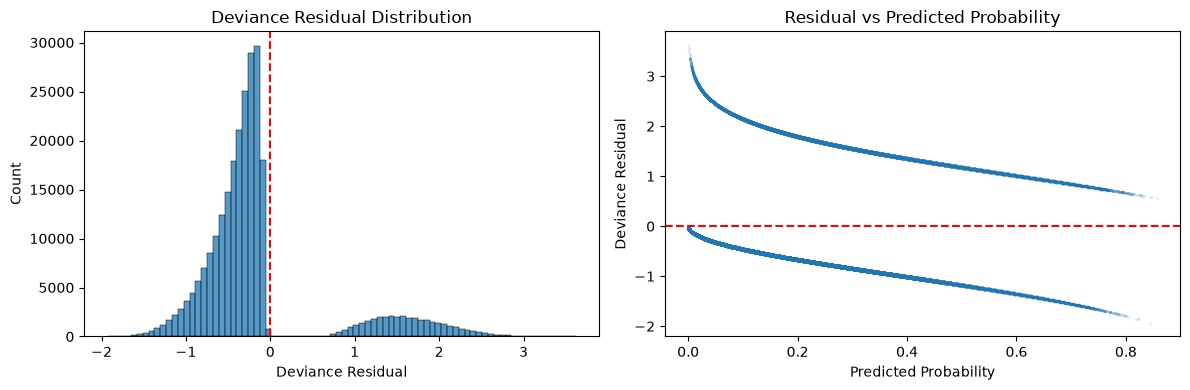

In [61]:
# 繪製 residual distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Deviance Residual Distribution
sns.histplot(
    dev_resid,
    bins=80,
    ax=axes[0]
)

axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Deviance Residual Distribution")
axes[0].set_xlabel("Deviance Residual")

# 2. Deviance Residual vs Predicted Probability
axes[1].scatter(
    p_hat,
    dev_resid,
    s=2,
    alpha=0.08
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residual vs Predicted Probability")
axes[1].set_xlabel("Predicted Probability")
axes[1].set_ylabel("Deviance Residual")

plt.tight_layout()
plt.show()

## Threshold

#### 0.5/Youden's J/screening

In [ ]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Predicted probabilities
y_true = np.asarray(y)
p_hat = np.asarray(refined_model.predict(X_refined))

# 2. ROC Curve
fpr, tpr, roc_thresholds = roc_curve(y_true, p_hat)

# 3. Default Threshold
t_default = 0.5

# 4. Youden's J Threshold
J = tpr - fpr
best_idx = np.argmax(J)
t_youden = roc_thresholds[best_idx]

# 5. Screening Threshold: Sensitivity >= 80%
target_sensitivity = 0.80

valid_idx = np.where(
    (tpr >= target_sensitivity) &
    np.isfinite(roc_thresholds)
)[0]

t_screening = roc_thresholds[valid_idx[0]]

thresholds = {
    "Default (0.5)": t_default,
    "Youden's J": t_youden,
    "Screening (Sensitivity >= 80%)": t_screening
}

print("=== Selected Thresholds ===")

for name, threshold in thresholds.items():
    print(f"{name}: {threshold:.4f}")

print(f"\nROC-AUC: {roc_auc_score(y_true, p_hat):.4f}")

=== Selected Thresholds ===
Default (0.5): 0.5000
Youden's J: 0.1261
Screening (Sensitivity >= 80%): 0.1286

ROC-AUC: 0.8274


In [15]:
# 比較三種threshold對TP、FP、FN、TN 的影響。

results = []

for name, threshold in thresholds.items():

    y_pred = (p_hat >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    results.append({
        "Method": name,
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

# Display results as text, instead of a table
for _, row in results_df.iterrows():

    print(f"\n=== {row['Method']} ===")
    print(f"Threshold: {row['Threshold']:.4f}")

    print(f"TP: {int(row['TP'])}")
    print(f"FP: {int(row['FP'])}")
    print(f"FN: {int(row['FN'])}")
    print(f"TN: {int(row['TN'])}")

    print(f"Accuracy: {row['Accuracy']:.4f}")
    print(f"Sensitivity: {row['Sensitivity']:.4f}")
    print(f"Specificity: {row['Specificity']:.4f}")
    print(f"Precision: {row['Precision']:.4f}")
    print(f"F1-score: {row['F1']:.4f}")


=== Default (0.5) ===
Threshold: 0.5000
TP: 6063
FP: 4781
FN: 29283
TN: 213553
Accuracy: 0.8657
Sensitivity: 0.1715
Specificity: 0.9781
Precision: 0.5591
F1-score: 0.2625

=== Youden's J ===
Threshold: 0.1261
TP: 28489
FP: 66377
FN: 6857
TN: 151957
Accuracy: 0.7113
Sensitivity: 0.8060
Specificity: 0.6960
Precision: 0.3003
F1-score: 0.4376

=== Screening (Sensitivity >= 80%) ===
Threshold: 0.1286
TP: 28277
FP: 65259
FN: 7069
TN: 153075
Accuracy: 0.7149
Sensitivity: 0.8000
Specificity: 0.7011
Precision: 0.3023
F1-score: 0.4388


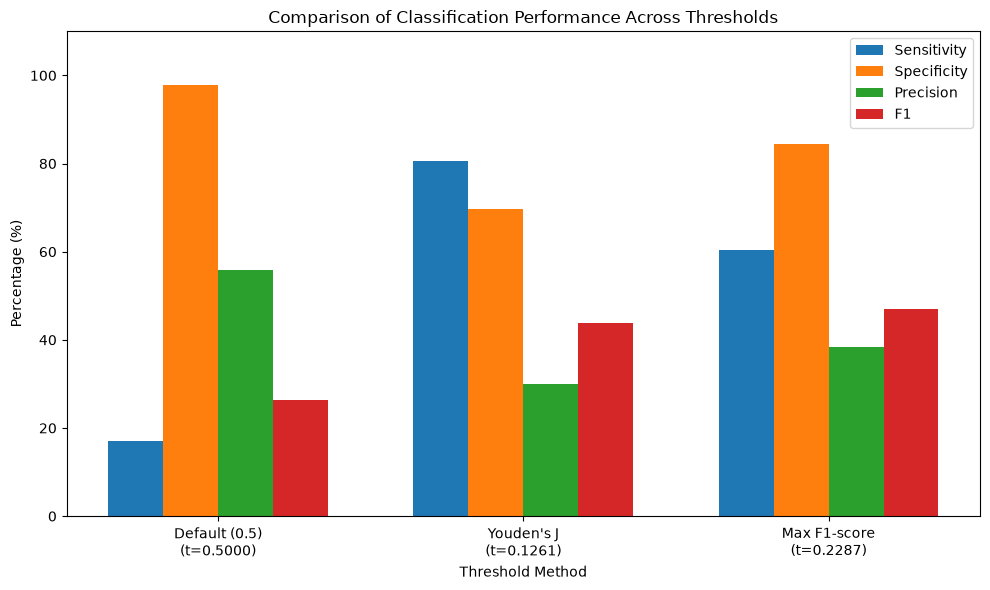

In [29]:
# plot
# compare

plot_df = results_df.copy()

metrics = ["Sensitivity", "Specificity", "Precision", "F1"]
x = np.arange(len(plot_df))
width = 0.18

plt.figure(figsize=(10, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + i * width,
        plot_df[metric] * 100,
        width=width,
        label=metric
    )

plt.xticks(
    x + width * 1.5,
    [f"{m}\n(t={t:.4f})" for m, t in zip(plot_df["Method"], plot_df["Threshold"])],
    rotation=0
)

plt.ylabel("Percentage (%)")
plt.xlabel("Threshold Method")
plt.title("Comparison of Classification Performance Across Thresholds")
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.show()

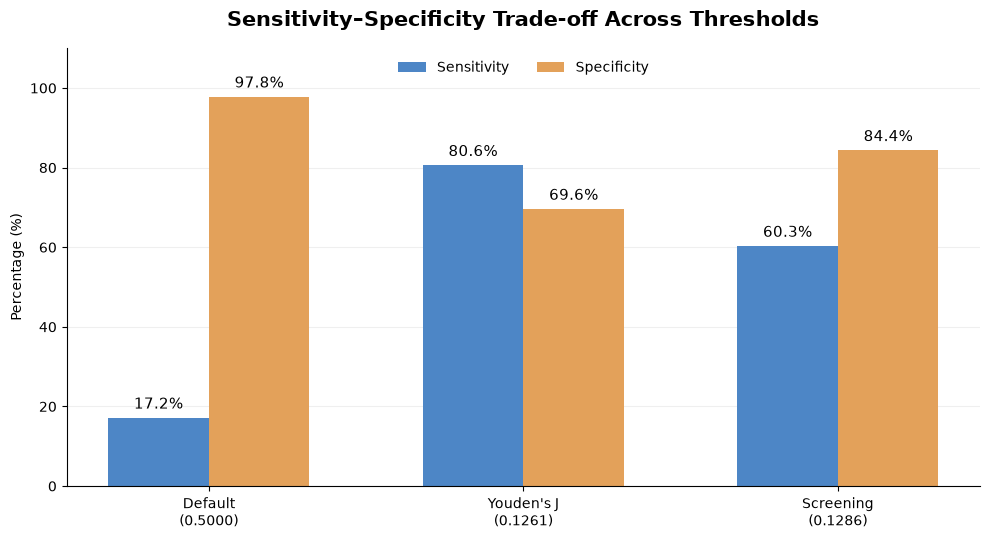

In [ ]:
# names = ["Default\n(0.5000)",
#          "Youden's J\n(0.1261)",
#          "Screening\n(0.1286)"]

# sensitivity = results_df["Sensitivity"].to_numpy() * 100
# specificity = results_df["Specificity"].to_numpy() * 100

# x = np.arange(3)
# width = 0.32

# fig, ax = plt.subplots(figsize=(10, 5.5))

# bars1 = ax.bar(
#     x - width / 2, sensitivity, width,
#     label="Sensitivity", color="#4D86C6"
# )

# bars2 = ax.bar(
#     x + width / 2, specificity, width,
#     label="Specificity", color="#E3A15A"
# )

# ax.bar_label(bars1, fmt="%.1f%%", padding=4, fontsize=11)
# ax.bar_label(bars2, fmt="%.1f%%", padding=4, fontsize=11)

# ax.set_xticks(x, names)
# ax.set_ylim(0, 110)
# ax.set_ylabel("Percentage (%)")
# ax.set_title(
#     "Sensitivity–Specificity Trade-off Across Thresholds",
#     fontsize=15, fontweight="bold", pad=16
# )

# ax.legend(frameon=False, ncol=2, loc="upper center")
# ax.grid(axis="y", alpha=0.2)
# ax.set_axisbelow(True)

# for spine in ["top", "right"]:
#     ax.spines[spine].set_visible(False)

# plt.tight_layout()
# plt.savefig(
#     "threshold_comparison.png",
#     dpi=300, bbox_inches="tight"
# )
# plt.show()


#### 0.5/Youden's J/max F1 score

In [27]:
# 找出f1 score最大化的 threshold

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Actual outcome and predicted probabilities
y_true = np.asarray(y)
p_hat = np.asarray(refined_model.predict(X_refined))

# 1. Default threshold
t_default = 0.5

# 2. Youden's J threshold
fpr, tpr, roc_thresholds = roc_curve(y_true, p_hat)
J = tpr - fpr
best_idx = np.argmax(J)
t_youden = roc_thresholds[best_idx]

# 3. F1-score maximizing threshold
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_true, p_hat)

# precision_recall_curve returns thresholds with length n-1
f1_scores = 2 * (pr_precision[:-1] * pr_recall[:-1]) / (pr_precision[:-1] + pr_recall[:-1] + 1e-12)
best_f1_idx = np.argmax(f1_scores)
t_f1 = pr_thresholds[best_f1_idx]

thresholds = {
    "Default (0.5)": t_default,
    "Youden's J": t_youden,
    "Max F1-score": t_f1
}

print("=== Selected Thresholds ===")
for name, threshold in thresholds.items():
    print(f"{name}: {threshold:.4f}")

print(f"\nROC-AUC: {roc_auc_score(y_true, p_hat):.4f}")
print(f"Best F1-score: {f1_scores[best_f1_idx]:.4f}")

=== Selected Thresholds ===
Default (0.5): 0.5000
Youden's J: 0.1261
Max F1-score: 0.2287

ROC-AUC: 0.8274
Best F1-score: 0.4693


In [28]:
results = []

for name, threshold in thresholds.items():
    y_pred = (p_hat >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    results.append({
        "Method": name,
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Accuracy": accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision,
        "F1": f1
    })

results_df = pd.DataFrame(results)

for _, row in results_df.iterrows():
    print(f"\n=== {row['Method']} ===")
    print(f"Threshold: {row['Threshold']:.4f}")
    print(f"TP: {int(row['TP'])}")
    print(f"FP: {int(row['FP'])}")
    print(f"FN: {int(row['FN'])}")
    print(f"TN: {int(row['TN'])}")
    print(f"Accuracy: {row['Accuracy']:.4f}")
    print(f"Sensitivity: {row['Sensitivity']:.4f}")
    print(f"Specificity: {row['Specificity']:.4f}")
    print(f"Precision: {row['Precision']:.4f}")
    print(f"F1-score: {row['F1']:.4f}")


=== Default (0.5) ===
Threshold: 0.5000
TP: 6063
FP: 4781
FN: 29283
TN: 213553
Accuracy: 0.8657
Sensitivity: 0.1715
Specificity: 0.9781
Precision: 0.5591
F1-score: 0.2625

=== Youden's J ===
Threshold: 0.1261
TP: 28489
FP: 66377
FN: 6857
TN: 151957
Accuracy: 0.7113
Sensitivity: 0.8060
Specificity: 0.6960
Precision: 0.3003
F1-score: 0.4376

=== Max F1-score ===
Threshold: 0.2287
TP: 21313
FP: 34164
FN: 14033
TN: 184170
Accuracy: 0.8100
Sensitivity: 0.6030
Specificity: 0.8435
Precision: 0.3842
F1-score: 0.4693


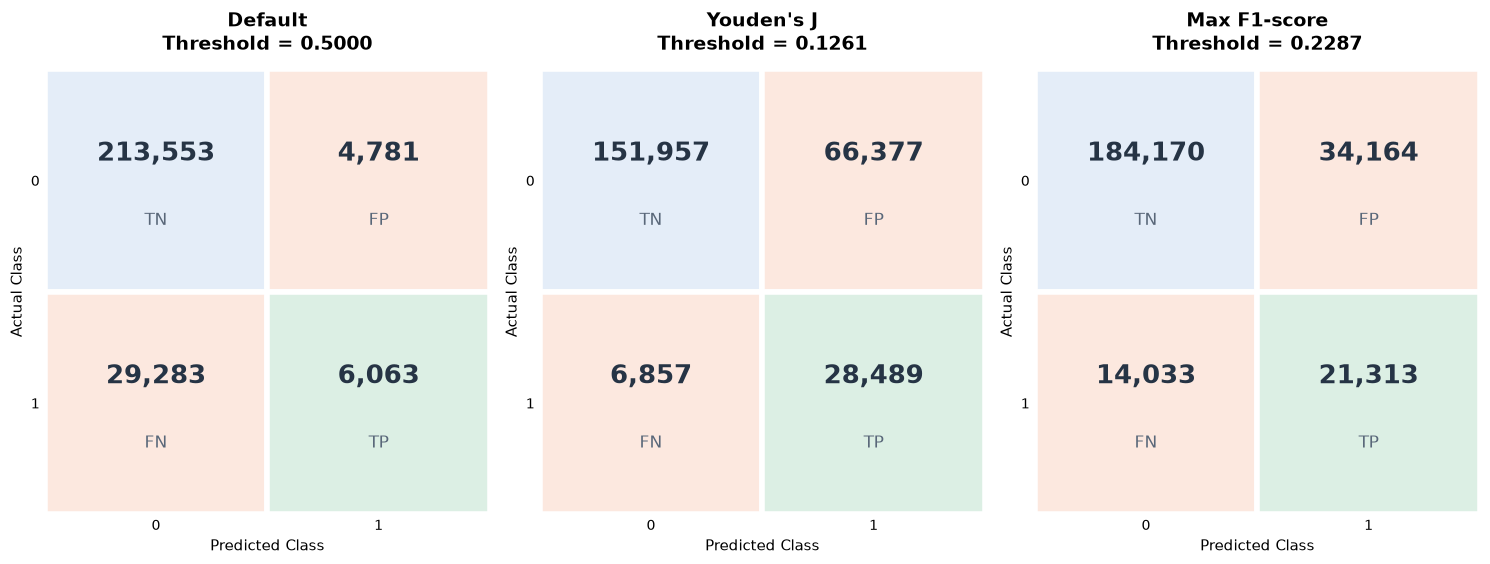

In [31]:
# plot
# confusion matrix

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))

colors = [
    ["#E4EDF8", "#FCE8DF"],  # TN, FP
    ["#FCE8DF", "#DCEFE4"]   # FN, TP
]
cell_names = [["TN", "FP"], ["FN", "TP"]]

short_names = ["Default", "Youden's J", "Max F1-score"]

for ax, (_, row), name in zip(
    axes, results_df.iterrows(), short_names
):
    cm = [
        [int(row["TN"]), int(row["FP"])],
        [int(row["FN"]), int(row["TP"])]
    ]

    for i in range(2):
        for j in range(2):
            ax.add_patch(Rectangle(
                (j, i), 1, 1,
                facecolor=colors[i][j],
                edgecolor="white",
                linewidth=4
            ))
            ax.text(
                j + 0.5, i + 0.38,
                f"{cm[i][j]:,}",
                ha="center", va="center",
                fontsize=19, fontweight="bold",
                color="#263445"
            )
            ax.text(
                j + 0.5, i + 0.68,
                cell_names[i][j],
                ha="center", va="center",
                fontsize=12, color="#596779"
            )

    ax.set_xlim(0, 2)
    ax.set_ylim(2, 0)
    ax.set_aspect("equal")
    ax.set_xticks([0.5, 1.5], ["0", "1"])
    ax.set_yticks([0.5, 1.5], ["0", "1"])
    ax.set_xlabel("Predicted Class", fontsize=11)
    ax.set_ylabel("Actual Class", fontsize=11)
    ax.set_title(
        f"{name}\nThreshold = {row['Threshold']:.4f}",
        fontsize=14, fontweight="bold", pad=14
    )
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.tight_layout()
plt.savefig(
    "threshold_confusion_matrices.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
